# 07 · Wister geothermal well 85-20

One well log and a pressure–temperature–spinner (PTS) survey from the Wister prospect, Imperial Valley,
California (DOE Geothermal Data Repository submission 904, CC BY 4.0). Download with `scripts/fetch_open_data.sh`
and set `SX_WISTER` to the `wister` folder.

## Setup

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Read the log and flag washouts
Caliper more than 2 in over the bit size (or the median caliper) marks bad hole.

In [2]:
import lasio, glob
ROOT = Path(os.environ.get("SX_WISTER", "data_public/california/wister")).resolve()
f = sorted(glob.glob(str(ROOT / "Wister_85-20_Run1_AIT-SP-GR-CALI/*.las")))[0]
df = lasio.read(f).df().reset_index()
dep = df.columns[0]
pick = lambda *names: next((c for c in df.columns if any(c.upper().startswith(n) for n in names)), None)
gr, cal, res, bs = pick("GR"), pick("HCAL", "CALI", "C1"), pick("AT90", "AHT90", "RT", "AF90"), pick("BS", "BIT")
nom = df[bs].ffill().bfill() if bs and df[bs].notna().any() else np.nanmedian(df[cal])
bad = (df[cal] - nom) > 2.0
print("curves:", gr, cal, res, "| bad-hole share", f"{bad.mean():.1%}")

curves: GR HCAL AF90 | bad-hole share 13.5%


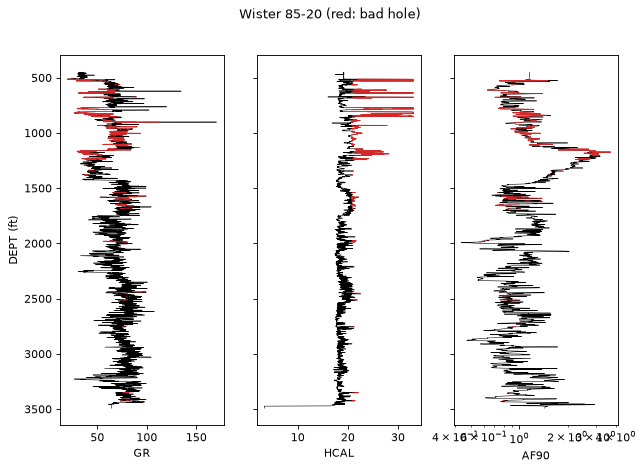

In [3]:
tracks = [c for c in (gr, cal, res) if c]
fig, axs = plt.subplots(1, len(tracks), figsize=(3 * len(tracks), 6), sharey=True)
for ax, c in zip(np.atleast_1d(axs), tracks):
    ax.plot(df[c], df[dep], lw=0.5, color="k"); ax.plot(df[c].where(bad), df[dep], lw=0.8, color="tab:red")
    if c == res: ax.set_xscale("log")
    ax.set_xlabel(c)
axs[0].invert_yaxis(); axs[0].set_ylabel(f"{dep} (ft)"); fig.suptitle("Wister 85-20 (red: bad hole)")
save(fig, "07_wister_tracks.png")

## PTS survey
`load_pts` reads every pass, converts to degC and MPa, and warns about passes without depth.

,rows,max_temp_c
pass_name,,
BHPT,412,169.605556
POOH-1,494,169.572222
RIH-1,471,168.500000


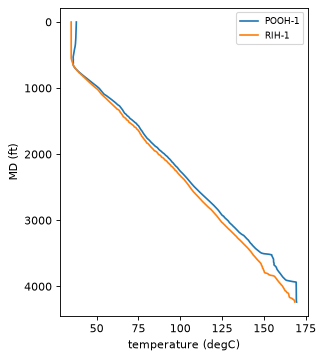

In [4]:
import warnings
from subsurfix.edges import PtsSource, load_pts
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    pts = load_pts([PtsSource(path=str(ROOT / "Wister%2085-20%20PTS%20survey%208-30-11.xls"), well="85-20")]).to_pandas()
for w in caught: print("warning:", w.message)
fig, ax = plt.subplots(figsize=(4, 5))
for name, g in pts[pts.depth_tied].groupby("pass_name"):
    ax.plot(g.temp_c, g.md_ft, label=name)
ax.invert_yaxis(); ax.set_xlabel("temperature (degC)"); ax.set_ylabel("MD (ft)"); ax.legend(fontsize=8)
save(fig, "07_wister_pts.png")
pts.groupby("pass_name").agg(rows=("seq", "size"), max_temp_c=("temp_c", "max"))